#### aplicaremos aprendizaje no supervisado mas activo para poder realizar un modelo en base a un dt que cree basandome en las iamgenes sacadas por los estudiantes de IA2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import random
from matplotlib.colors import ListedColormap
import pandas as pd 

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [3]:
import os
from PIL import Image

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
ruta = "dt_creado"
LADO = 80
t_esperado = (LADO, LADO)

invalidas = 0
total = 0

for carpeta, _, archivos in os.walk(ruta):
    for archivo in archivos:
        if archivo.lower().endswith((".png", ".jpg", ".jpeg")):
            total += 1
            ruta_img = os.path.join(carpeta, archivo)
            try:
                with Image.open(ruta_img) as img:
                    if img.size != t_esperado:
                        print(f"[Diferente] {archivo} mide {img.size} (esperado {t_esperado}) en: {carpeta}")
                        invalidas += 1
            except Exception as e:
                print(f"[Error] No se pudo abrir {archivo}: {e}")
                invalidas += 1

print(f"\n--- Resultado de la validación ---")
print(f"Total de imágenes revisadas: {total}")
if invalidas == 0:
    print("¡Todas las imágenes cumplen exactamente con el tamaño de 80x80!")
else:
    print(f"Atención: Se encontraron {invalidas} imágenes que no cumplen con el tamaño requerido.") 


--- Resultado de la validación ---
Total de imágenes revisadas: 1268
¡Todas las imágenes cumplen exactamente con el tamaño de 80x80!


In [6]:
ruta = "dt_creado"
LADO = 80 

rutas = []
for carpeta, _, archivos in os.walk(ruta):
    for archivo in archivos:
        if archivo.lower().endswith((".png", ".jpg", ".jpeg")):
            rutas.append(os.path.join(carpeta, archivo))
print(len(rutas), "imágenes encontradas")

rng = np.random.default_rng(42)
rng.shuffle(rutas)

def cargar(r):
    img = Image.open(r).convert("RGB").resize((LADO, LADO))
    return np.asarray(img, dtype=np.float32).ravel()

dt_creado = pd.DataFrame([cargar(r) for r in rutas])
print(dt_creado.shape)
dt_creado.head()

1268 imágenes encontradas
(1268, 19200)


,0,1,2,3,4,5,6,7,8,9,...,19190,19191,19192,19193,19194,19195,19196,19197,19198,19199
0,36.0,27.0,33.0,44.0,33.0,37.0,62.0,45.0,47.0,56.0,...,94.0,171.0,130.0,99.0,136.0,102.0,81.0,147.0,108.0,87.0
1,101.0,115.0,115.0,65.0,79.0,82.0,62.0,74.0,76.0,59.0,...,31.0,39.0,32.0,32.0,44.0,37.0,34.0,45.0,38.0,33.0
2,110.0,97.0,89.0,75.0,69.0,67.0,112.0,118.0,126.0,73.0,...,191.0,201.0,195.0,180.0,211.0,204.0,192.0,200.0,193.0,184.0
3,134.0,103.0,101.0,139.0,111.0,110.0,145.0,115.0,115.0,144.0,...,67.0,80.0,69.0,67.0,76.0,65.0,59.0,79.0,71.0,61.0
4,204.0,190.0,180.0,238.0,226.0,215.0,255.0,255.0,249.0,255.0,...,108.0,238.0,205.0,180.0,181.0,149.0,130.0,82.0,58.0,48.0


In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test = train_test_split(dt_creado, test_size=40, random_state=42)

print("Forma de X_train (todo el resto):", X_train.shape)
print("Forma de X_test (exactamente 40):", X_test.shape)

Forma de X_train (todo el resto): (1228, 19200)
Forma de X_test (exactamente 40): (40, 19200)


In [8]:
X_train = X_train.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

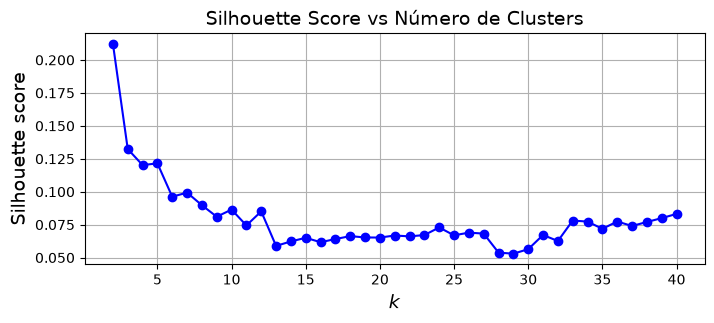

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50, random_state=42)
X = pca.fit_transform(X_train) 

max_k = 40 
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, max_k + 1)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

ks = list(range(2, max_k + 1))



plt.figure(figsize=(8, 3))
plt.plot(ks, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()

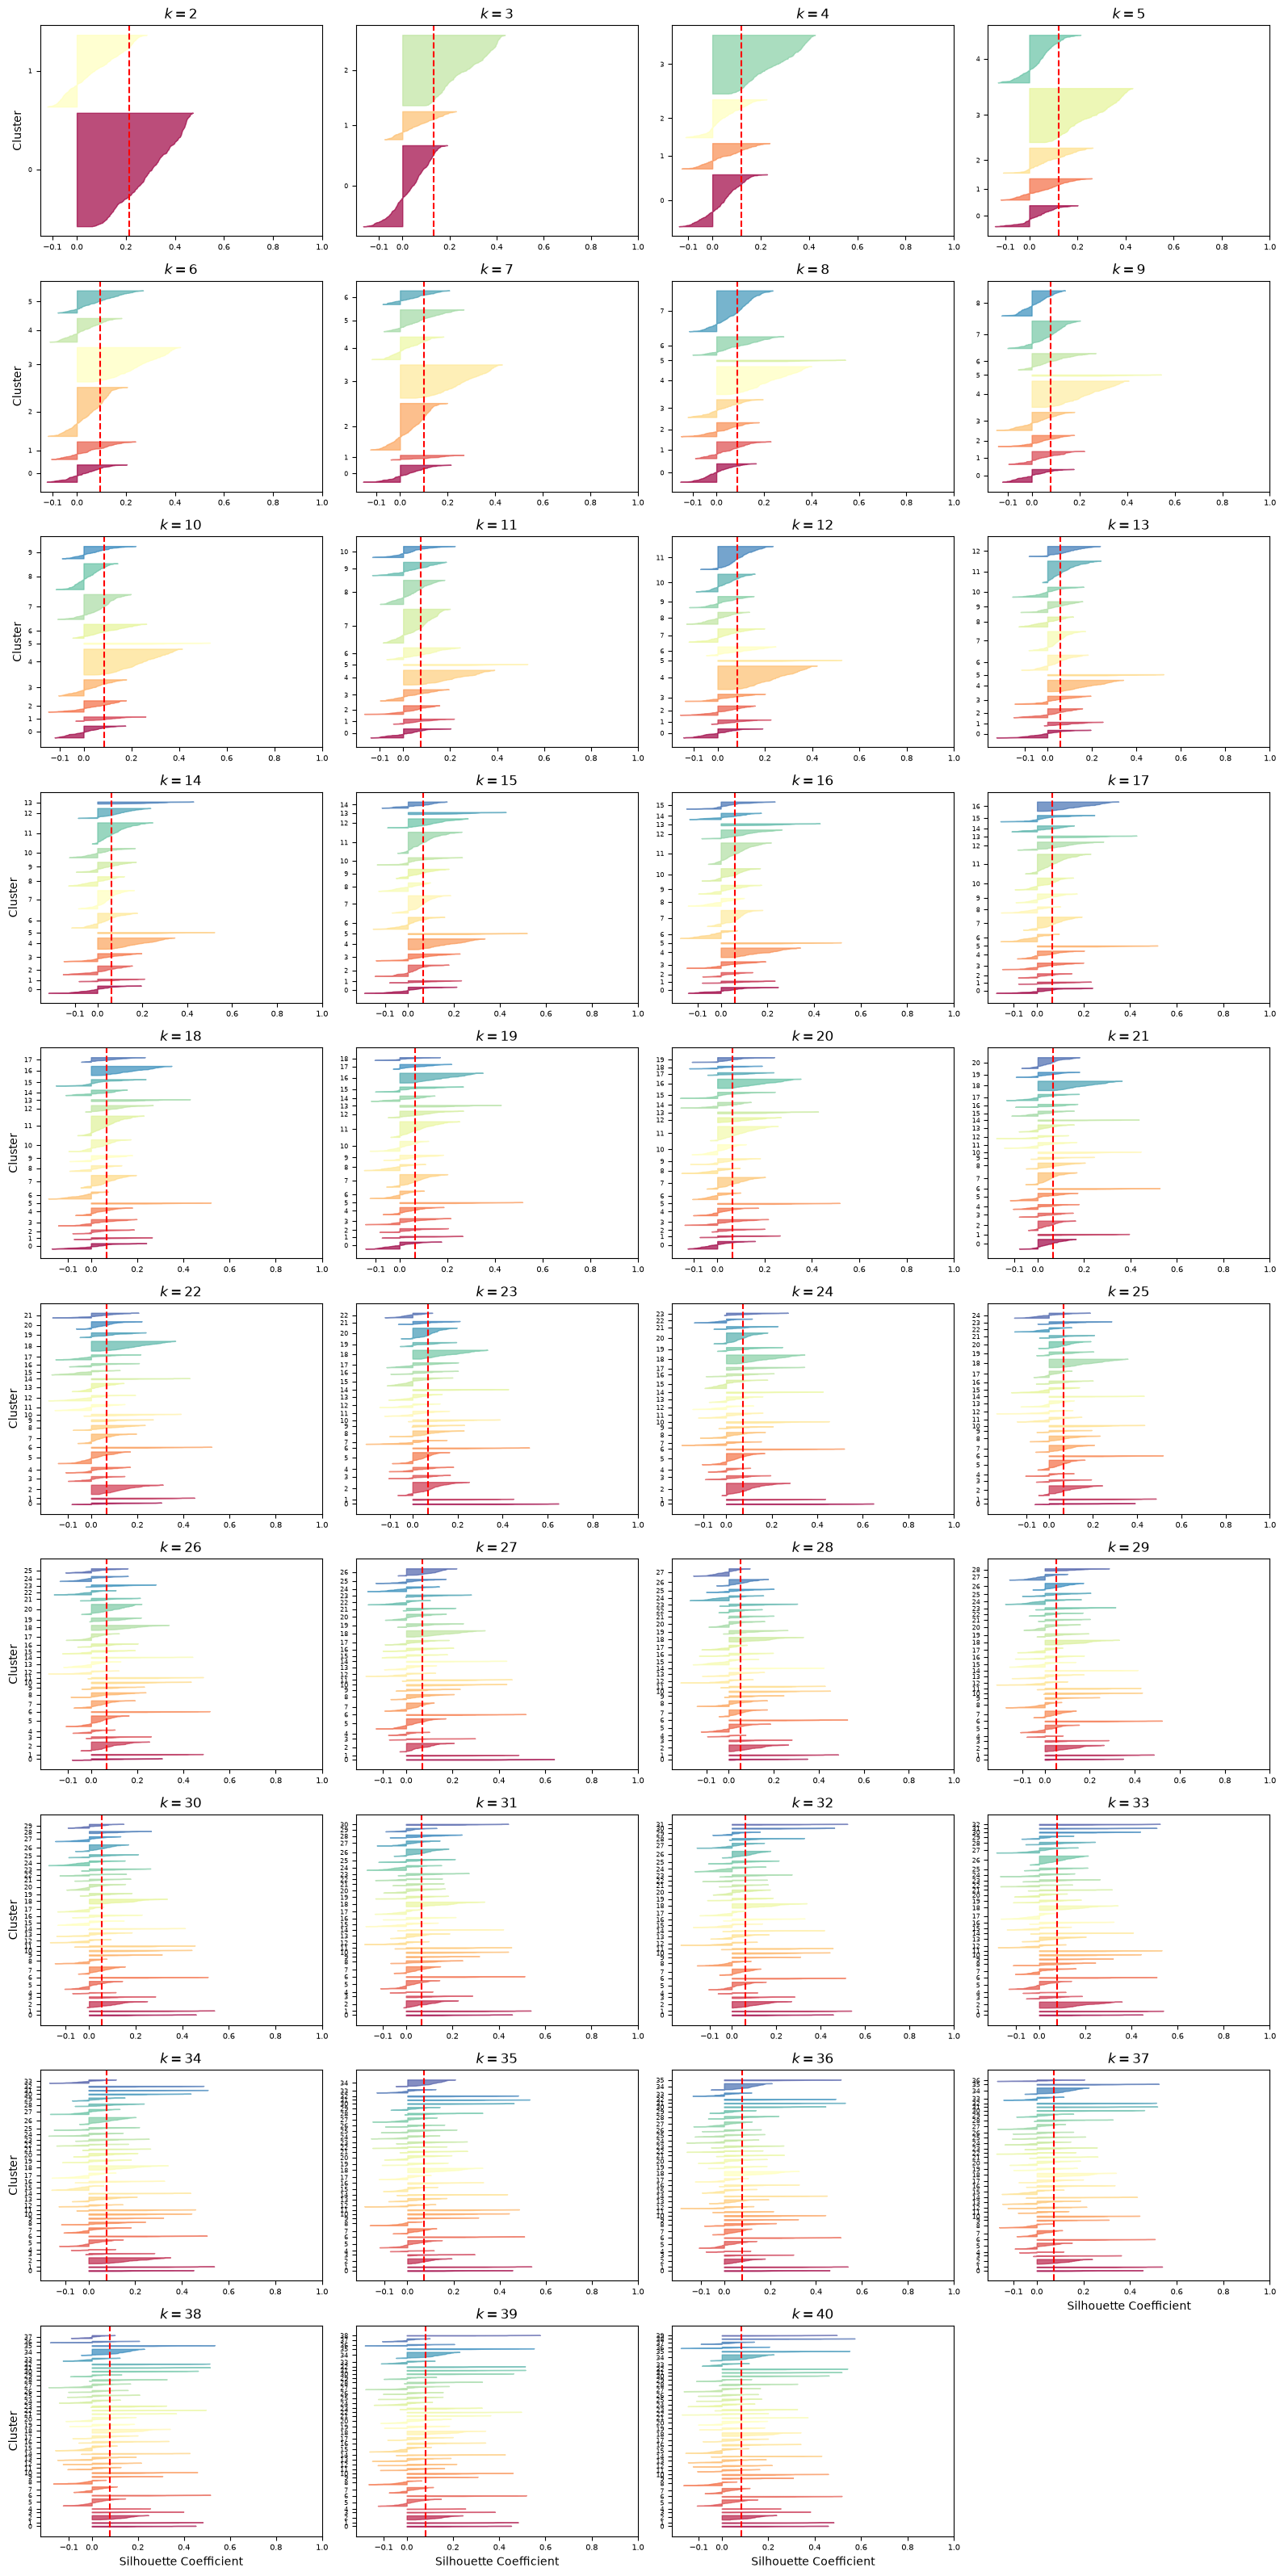

In [10]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

valid_ks = ks                                   
n_cols = 4                                  
n_rows = int(np.ceil(len(valid_ks) / n_cols))  

plt.figure(figsize=(4 * n_cols, 3.2 * n_rows)) 

for plot_idx, k in enumerate(valid_ks):
    plt.subplot(n_rows, n_cols, plot_idx + 1) 

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    plt.tick_params(axis='y', labelsize=6)                        

    if plot_idx % n_cols == 0:                                     
        plt.ylabel("Cluster")

    plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])      
    plt.tick_params(axis='x', labelsize=7)
    if plot_idx >= len(valid_ks) - n_cols:              
        plt.xlabel("Silhouette Coefficient")

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=12)

plt.tight_layout()                                            
plt.show()

In [28]:
from sklearn.cluster import KMeans

k = 30
kmeans = KMeans(n_clusters=k, random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)

print(X_digits_dist.shape)

(1228, 30)


In [29]:
print(X_digits_dist.shape)
print(X_digits_dist)

(1228, 30)
[[41.88811244 34.44796893 44.98346879 ... 29.71176859 32.63192661
  37.59513678]
 [36.39053812 31.9682245  51.14998548 ... 32.75137901 44.04483443
  32.3760151 ]
 [48.33272354 39.78562867 46.98166076 ... 35.05177024 41.80873189
  44.00755387]
 ...
 [32.4498693  27.93221391 49.93243955 ... 28.81131887 37.26897573
  29.65927007]
 [29.80320923 24.87018536 55.40237712 ... 27.93921786 42.4120116
  26.28526232]
 [29.8346784  19.82601251 47.46076192 ... 20.08362645 36.07260797
  18.31206306]]


In [30]:
idxs = np.argmin(X_digits_dist, axis=0)
X_representative_digits = X_train.values[idxs]

In [31]:
print(X_representative_digits.shape)
print(X_representative_digits)

(30, 19200)
[[0.17254902 0.22352941 0.11764706 ... 0.47058824 0.41960784 0.36862745]
 [0.43529412 0.37254902 0.34117647 ... 0.28235294 0.25882353 0.28627451]
 [0.43921569 0.66666667 0.98823529 ... 0.31372549 0.25098039 0.25490196]
 ...
 [0.35294118 0.31764706 0.29803922 ... 0.38823529 0.35686275 0.38039216]
 [0.45098039 0.6745098  0.99215686 ... 0.42352941 0.40392157 0.28235294]
 [0.17254902 0.16470588 0.1372549  ... 0.25882353 0.21960784 0.18039216]]


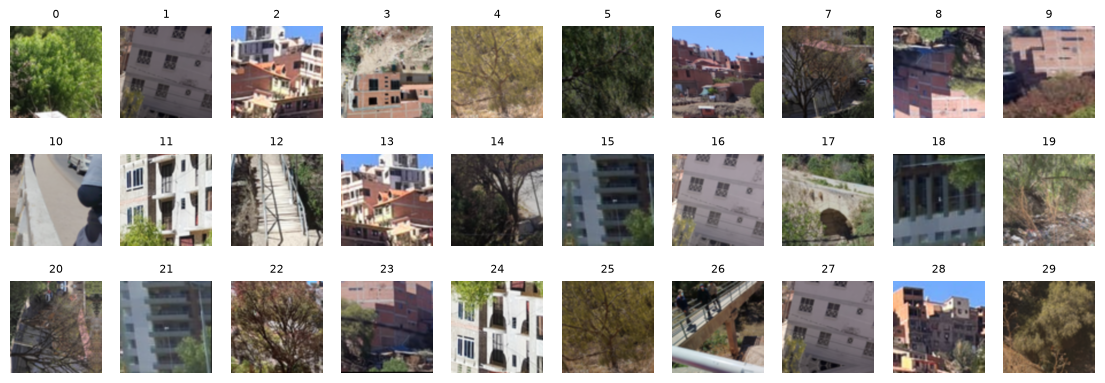

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
for index, X_representative_digit in enumerate(X_representative_digits):
  plt.subplot(5, 10, index+1)
  plt.imshow(X_representative_digit.reshape(80, 80, 3), interpolation="bicubic")
  plt.title(index, fontsize=8)
  plt.axis('off')
plt.show()

In [33]:
y_representative_digits = np.array([
    "arboles", "casas", "casas", "casas", "arboles", "arboles", "casas", "arboles", "casas", "casas", "puentes", "casas", "puentes", "casas", "arboles", "casas", "casas", "puentes", "casas", "arboles", "arboles", "casas", "arboles", "casas", "casas", "arboles", "puentes", "casas", "casas", "arboles"])
print(len(y_representative_digits))

30


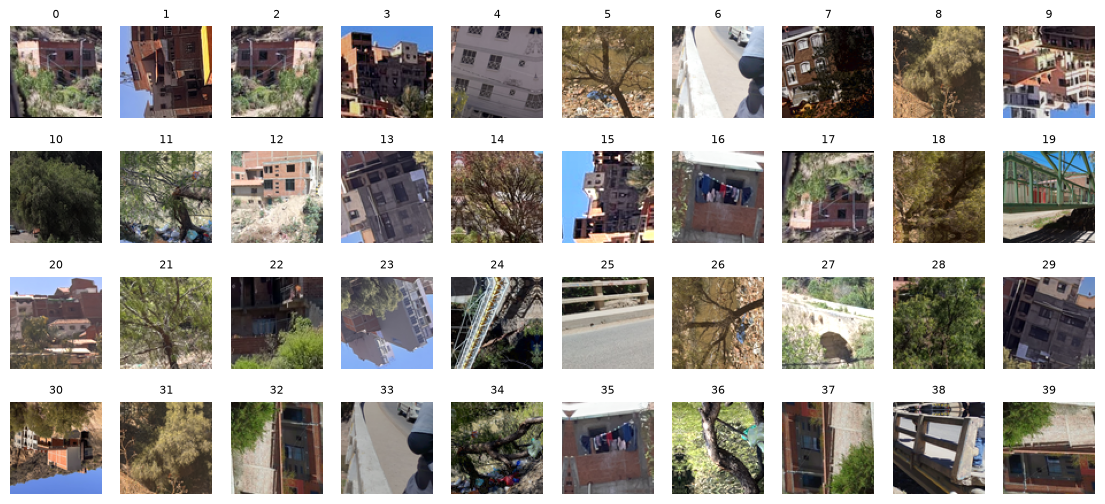

In [35]:
plt.figure(figsize=(14, 16))
for index, img in enumerate(X_test.values):
  plt.subplot(10, 10, index+1)
  plt.imshow(img.reshape(80, 80, 3))
  plt.title(index, fontsize=8)
  plt.axis('off')
plt.show()

In [39]:
y_test = np.array([
"casas", "casas", "casas", "casas", "casas", "arboles", "puentes", "casas", "arboles", "casas", "arboles", "arboles", "casas", "casas", "arboles", "casas", "casas", "casas", "arboles", "puentes", "casas", "arboles", "casas", "casas", "puentes", "puentes", "arboles", "puentes", "arboles", "casas", "casas", "arboles", "casas", "puentes", "arboles", "casas", "arboles", "casas", "puentes", "casas"])
print(len(y_test))

40


In [40]:
from sklearn.linear_model import LogisticRegression

log_reg2 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg2.fit(X_representative_digits, y_representative_digits)
log_reg2.score(X_test, y_test)

CPU times: total: 688 ms
Wall time: 500 ms


0.725

In [ ]:
y_train_propagated = np.empty(len(X_train), dtype=object) 
for i in range(k):
  y_train_propagated[kmeans.labels_==i] = y_representative_digits[i]

In [42]:
log_reg3 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg3.fit(X_train[:1000], y_train_propagated[:1000])
log_reg3.score(X_test, y_test)

CPU times: total: 3min 46s
Wall time: 18.3 s


0.575

In [43]:
for digito in np.unique(y_representative_digits):
    grupos = np.where(y_representative_digits == digito)[0]
    print(f"Dígito {digito}: grupos {grupos}")

Dígito arboles: grupos [ 0  4  5  7 14 19 20 22 25 29]
Dígito casas: grupos [ 1  2  3  6  8  9 11 13 15 16 18 21 23 24 27 28]
Dígito puentes: grupos [10 12 17 26]


In [45]:
probas = log_reg3.predict_proba(X_train[:1000])
labels_ixs = np.argmax(probas, axis=1)
labels = np.array([proba[ix] for proba, ix in zip(probas, labels_ixs)])
sorted_ixs = np.argsort(labels)
labels[sorted_ixs[:10]]

array([0.52994132, 0.5386537 , 0.55305362, 0.582379  , 0.60233826,
       0.61452052, 0.61705417, 0.62038537, 0.62252757, 0.62489218])

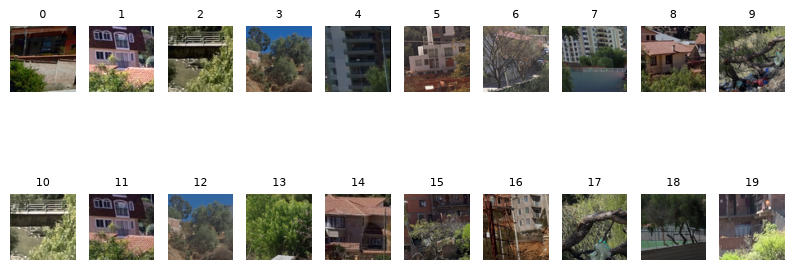

In [ ]:
n_consulta = 20                                                  

X_lowest = X_train.values[:1000][sorted_ixs[:n_consulta]]
plt.figure(figsize=(10, 4))
for index, img in enumerate(X_lowest):
    plt.subplot(int(np.ceil(n_consulta / 10)), 10, index + 1)   
    plt.imshow(img.reshape(80, 80, 3))                              
    plt.title(index, fontsize=8)                                 
    plt.axis('off')
plt.show()

In [48]:
y_lowest = np.array([
    "casas", "casas", "puentes", "arboles", "casas", "casas", "arboles", "casas", "casas", "arboles", "puentes", "casas", "arboles", "arboles", "casas", "casas", "casas", "arboles", "arboles", "casas"
])
assert len(y_lowest) == n_consulta

In [49]:
print(y_train_propagated[:1000][sorted_ixs[:n_consulta]])

[np.str_('casas') np.str_('arboles') np.str_('casas') np.str_('arboles')
 np.str_('arboles') np.str_('casas') np.str_('casas') np.str_('arboles')
 np.str_('arboles') np.str_('arboles') np.str_('arboles') np.str_('casas')
 np.str_('casas') np.str_('arboles') np.str_('arboles') np.str_('arboles')
 np.str_('arboles') np.str_('arboles') np.str_('arboles')
 np.str_('arboles')]


In [50]:
y_train2 = y_train_propagated[:1000].copy()
y_train2[sorted_ixs[:n_consulta]] = y_lowest

In [ ]:
log_reg5 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)   
%time log_reg5.fit(X_train[:1000], y_train2)
log_reg5.score(X_test, y_test)

CPU times: total: 2min 20s
Wall time: 12.7 s


0.6

In [52]:
ya_corregidas = np.zeros(1000, dtype=bool)
ya_corregidas[sorted_ixs[:n_consulta]] = True      

probas = log_reg5.predict_proba(X_train[:1000])
labels_ixs = np.argmax(probas, axis=1)
labels = np.array([proba[ix] for proba, ix in zip(probas, labels_ixs)])
labels[ya_corregidas] = 2                              
sorted_ixs = np.argsort(labels)

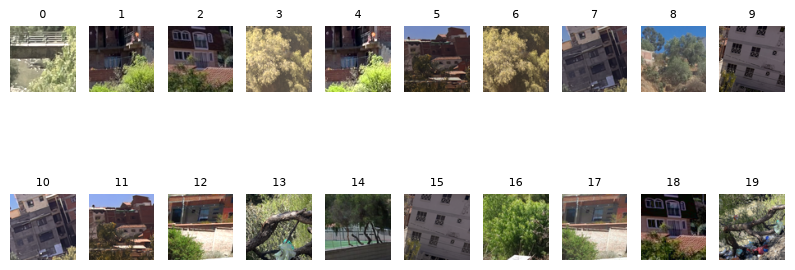

In [53]:
n_consulta = 20                                                

X_lowest = X_train.values[:1000][sorted_ixs[:n_consulta]]
plt.figure(figsize=(10, 4))
for index, img in enumerate(X_lowest):
    plt.subplot(int(np.ceil(n_consulta / 10)), 10, index + 1)  
    plt.imshow(img.reshape(80, 80, 3))
    plt.title(index, fontsize=8)                       
    plt.axis('off')
plt.show()

In [54]:
y_lowest = np.array([
    "puentes", "casas", "casas", "arboles", "casas", "casas", "arboles", "casas", "arboles", "casas", "casas", "casas", "casas", "arboles", "arboles", "casas", "arboles", "casas", "casas", "arboles"
])
assert len(y_lowest) == n_consulta

In [55]:
y_train3 = y_train2.copy()                            
y_train3[sorted_ixs[:n_consulta]] = y_lowest            
log_reg6 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
log_reg6.fit(X_train[:1000], y_train3)
log_reg6.score(X_test, y_test)

0.625